# Lead Scoring for WhatsApp Campaigns

**Data Science Challenge** · Author: Solano Jacon

A custom hair-care e-commerce company sends WhatsApp messages to every person who fills out its product questionnaire (a *lead*). The goal is to find which leads are most likely to buy, so the messages can go to the right people. [Challenge description](README.md).

**Summary**

- Only **12.7% of leads buy**. Age, returning visits, device and acquisition channel separate buyers from non-buyers most clearly.
- A gradient boosting model trained on January–April 2022 and tested on May–June 2022 ranks leads with a **ROC AUC of 0.67**.
- The **top 10% of leads convert at 29%**, about twice the average rate.
- Messaging only the **top half of leads reaches 71% of buyers** with half the cost.

**Contents**

1. Data reading and normalization
2. Who buys? Exploratory analysis
3. Feature engineering and selection
4. Train/test split
5. Algorithm choice
6. Model training
7. Saving, loading and scoring
8. Final results
9. What drives a purchase
10. Conclusions and next steps

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.inspection import permutation_importance

DATA_PATH = '../../portfolio-data/Lead_Scoring_for_WhatsApp_Campaigns/data/data.csv'
MODEL_PATH = '../../portfolio-data/Lead_Scoring_for_WhatsApp_Campaigns/lead_scoring_pipeline.joblib'
SPLIT_DATE = '2022-05-01'   # train: Jan-Apr 2022 / test: May-Jun 2022
RANDOM_STATE = 42

In [2]:
# Chart style
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#8a8985'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'font.size': 10, 'legend.frameon': False,
    'lines.linewidth': 2,
})
pct = lambda x, d=1: f'{x:.{d}%}'

## 1. Data reading and normalization

### 1.1 Extraction

The company's PostgreSQL database has three tables: `forms` (one row per questionnaire), `orders` and `order_items`. The extract below joins each form with its order items, so a form that turned into a purchase appears once per item bought:

```sql
SELECT f.*, oi.id_pedido, oi.id
FROM forms AS f
LEFT OUTER JOIN order_items AS oi ON f.id_form = oi.id_form
```

The extract was saved to CSV, which is the source used in this notebook.

In [3]:
raw = pd.read_csv(DATA_PATH, index_col=0, encoding='iso-8859-1')
print(f'{len(raw):,} rows x {raw.shape[1]} columns')
raw.head(3)

585,472 rows x 25 columns


,id_form,id_cliente,data,sistema_operacional,navegador,localizacao,locale,cidade,estado,qtde_lavagem_semana,...,tempo_procedimento,dieta,atividade_fisica,frequencia_estresse,caracteristica,faixa_etaria,efeitos_desejados,fragancia,id_pedido,id
0,c7d453c9c01223a42968d9fe136047,d2620a3e6f00a6dc6e88,2022-01-03 15:42:22,iOS,Safari,"São Paulo, Sao Paulo",BR,SÃO PAULO,SAO PAULO,4,...,Há 2 semanas,Celíaca,Frequente,Nunca,Característica 1,25 a 34,Efeito 7,Rosas,5d2301cb6bf9d7c,426190.0
1,c7d453c9c01223a42968d9fe136047,d2620a3e6f00a6dc6e88,2022-01-03 15:42:22,iOS,Safari,"São Paulo, Sao Paulo",BR,SÃO PAULO,SAO PAULO,4,...,Há 2 semanas,Celíaca,Frequente,Nunca,Característica 1,25 a 34,Efeito 7,Rosas,5d2301cb6bf9d7c,426189.0
2,c7d453c9c01223a42968d9fe136047,d2620a3e6f00a6dc6e88,2022-01-03 15:42:22,iOS,Safari,"São Paulo, Sao Paulo",BR,SÃO PAULO,SAO PAULO,4,...,Há 2 semanas,Celíaca,Frequente,Nunca,Característica 1,25 a 34,Efeito 7,Rosas,5d2301cb6bf9d7c,426188.0


### 1.2 One row per lead

The model has to score **leads**, so the unit of analysis is the form. The join returns one row per order item, which repeats each buyer about four times. The cells below collapse the extract to one row per form, with a binary target `bought`.

Keeping the item-level rows would weight buyers by basket size and, worse, place copies of the same lead in both the training and the test data.

In [4]:
raw['bought'] = raw['id_pedido'].notna().astype(int)

rows_per_form = raw.groupby('id_form').agg(bought=('bought', 'max'), rows=('bought', 'size'))
rows_per_form.groupby('bought')['rows'].describe()[['mean', '50%', 'max']].rename(index={0: 'non-buyer', 1: 'buyer'})

,mean,50%,max
bought,,,
non-buyer,1.000000,1.0,1.0
buyer,3.909477,4.0,112.0


In [5]:
leads = (raw.sort_values('bought', ascending=False)
            .drop_duplicates('id_form')
            .drop(columns=['id_pedido', 'id']))
leads['data'] = pd.to_datetime(leads['data'])
leads = leads.sort_values('data').reset_index(drop=True)

assert leads['id_form'].is_unique
print(f'{len(leads):,} leads from {leads["id_cliente"].nunique():,} customers')
print(f'Period: {leads["data"].min():%Y-%m-%d} to {leads["data"].max():%Y-%m-%d}')
print(f'Share of leads that bought: {pct(leads["bought"].mean())}')

427,950 leads from 305,457 customers
Period: 2022-01-01 to 2022-06-30
Share of leads that bought: 12.7%


### 1.3 Data dictionary

The source columns are in Portuguese. They are renamed to English and their categorical values translated in the next step.

| Source column | Name used here | Description |
|---|---|---|
| `id_form` / `id_cliente` | `form_id` / `customer_id` | Form and customer identifiers |
| `data` | `created_at` | Form submission timestamp |
| `sistema_operacional`, `navegador` | `os`, `browser` | Device operating system and browser |
| `estado`, `cidade`, `localizacao`, `locale` | `state`, ... | Location (`locale` is always `BR`) |
| `utm_source` | `utm_source` | Acquisition channel |
| `qtde_lavagem_semana` | `washes_per_week` | Hair washes per week (1-7) |
| `tipo_cabelo`, `comprimento`, `tipo_fios` | `hair_type`, `hair_length`, `strand_type` | Hair description |
| `procedimentos`, `tempo_procedimento` | `procedures`, `time_since_procedure` | Chemical/physical procedures and how long ago |
| `dieta`, `atividade_fisica`, `frequencia_estresse` | `diet`, `physical_activity`, `stress` | Lifestyle |
| `caracteristica`, `efeitos_desejados` | `characteristics`, `desired_effects` | Multi-choice answers (anonymized as 1-10) |
| `faixa_etaria` | `age_range` | Age range |
| `fragancia` | `fragrance` | Chosen fragrance |
| `id_pedido` | `bought` | Target: the form led to an order |

### 1.4 Cleaning and translation

- Categorical values are trimmed and translated to English.
- Missing values become an explicit `missing` category, because a blank answer can itself be informative.
- Acquisition channels with typos or case variants are merged (`facebook ads` → `facebook`, `sf_wpp_flu` → `sf_wpp_flux`).

In [6]:
TRANSLATIONS = {
    'hair_length': {'Muito curto': 'very short', 'Raíz exposta': 'roots showing', 'Longo': 'long', 'Extra longo': 'extra long'},
    'strand_type': {'Secos': 'dry', 'Pontas duplas': 'split ends', 'Rebeldes': 'frizzy', 'Perfeitos': 'perfect'},
    'diet': {'Celíaca': 'celiac', 'Nenhuma restrição': 'no restriction', 'Intolerante a lactose': 'lactose intolerant', 'Leve': 'light'},
    'physical_activity': {'Raramente': 'rarely', 'Frequente': 'frequently', 'Sempre': 'always', 'Nunca': 'never', 'N/C': 'not informed'},
    'stress': {'Uma vez por mês': 'once a month', 'Nunca': 'never', 'Regularmente': 'regularly', 'Quase sempre': 'almost always'},
    'fragrance': {'Rosas': 'roses', 'Eucalipto': 'eucalyptus', 'Flores do campo': 'wildflowers'},
    'hair_type': {f'Tipo {i}': f'type {i}' for i in range(1, 5)},
}
AGE_RANGES = {'2 a 10': '2-10', '11 a 17': '11-17', '18 a 24': '18-24', '25 a 34': '25-34',
              '35 a 44': '35-44', '45 a 54': '45-54', '55 a 64': '55-64', '65+': '65+'}
TIME_SINCE_PROCEDURE = {'Não houve procedimentos': 0, 'Há 1 semana': 1, 'Há 2 semanas': 2, 'Há 1 mês': 3, 'Há mais de 1 mês': 4}
PROCEDURES = {'Corte agressivo': 'aggressive_cut', 'Exposição ao sol': 'sun_exposure', 'Tintura': 'dye',
              'Nenhum': 'none', 'Todos acima': 'all_of_the_above'}
UTM_FIXES = {'facebook ads': 'facebook', 'sf_wpp_flu': 'sf_wpp_flux'}

leads = leads.rename(columns={
    'id_form': 'form_id', 'id_cliente': 'customer_id', 'data': 'created_at',
    'sistema_operacional': 'os', 'navegador': 'browser', 'estado': 'state',
    'qtde_lavagem_semana': 'washes_per_week', 'tipo_cabelo': 'hair_type', 'comprimento': 'hair_length',
    'tipo_fios': 'strand_type', 'procedimentos': 'procedures', 'tempo_procedimento': 'time_since_procedure',
    'dieta': 'diet', 'atividade_fisica': 'physical_activity', 'frequencia_estresse': 'stress',
    'caracteristica': 'characteristics', 'faixa_etaria': 'age_range', 'efeitos_desejados': 'desired_effects',
    'fragancia': 'fragrance',
})
for column, mapping in TRANSLATIONS.items():
    leads[column] = leads[column].map(mapping)
leads['age_range'] = leads['age_range'].map(AGE_RANGES)

for column in ['os', 'browser', 'state', 'utm_source']:
    leads[column] = leads[column].astype('string').str.strip()
for column in ['state', 'utm_source']:
    leads[column] = leads[column].str.lower()
leads['utm_source'] = leads['utm_source'].replace(UTM_FIXES)
leads['state'] = leads['state'].replace({'null': pd.NA})

leads[['os', 'browser', 'state', 'utm_source', 'hair_type', 'diet', 'age_range']].sample(5, random_state=RANDOM_STATE)

,os,browser,state,utm_source,hair_type,diet,age_range
327083,Android,Chrome,rondonia,facebook,type 2,celiac,18-24
406484,Android,Chrome,espirito santo,influencer,type 2,celiac,18-24
316712,Android,Chrome,parana,influencer,type 2,celiac,35-44
321300,Android,Chrome,minas gerais,sf_wpp_camp,type 1,no restriction,35-44
243261,Android,Chrome,minas gerais,facebook,type 2,celiac,11-17


## 2. Who buys? Exploratory analysis

The challenge asks for the relationship between leads and buyers. Before modeling, the charts below compare the purchase rate across segments with the overall rate (dashed line).

A lead's **history** comes from earlier forms by the same customer: how many forms they had filled out before this one. It uses only past data, so it is also available when a new form arrives.

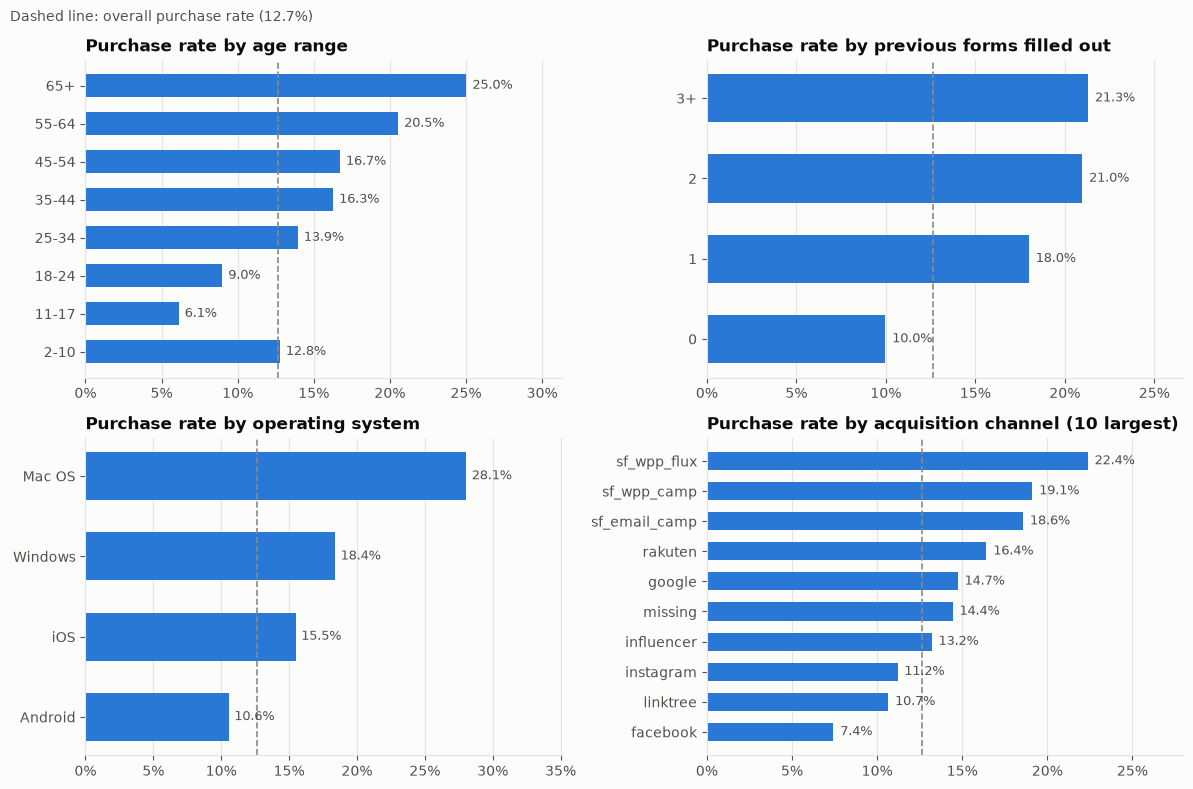

In [7]:
leads['previous_forms'] = leads.groupby('customer_id').cumcount()
leads['month'] = leads['created_at'].dt.to_period('M').astype(str)
OVERALL_RATE = leads['bought'].mean()

def rate_by(column, order=None, top=None, min_leads=1000):
    stats = leads.groupby(column, dropna=False)['bought'].agg(['mean', 'size'])
    stats = stats[stats['size'] >= min_leads]
    if top:
        stats = stats.sort_values('size', ascending=False).head(top)
    if order:
        stats = stats.reindex([o for o in order if o in stats.index])
    else:
        stats = stats.sort_values('mean')
    return stats

def bar_panel(ax, stats, title):
    labels = ['missing' if pd.isna(i) else str(i) for i in stats.index]
    ax.barh(labels, stats['mean'], color=BLUE, height=0.6)
    ax.axvline(OVERALL_RATE, color=GRAY, linestyle='--', linewidth=1.2)
    for y, value in enumerate(stats['mean']):
        ax.text(value + 0.004, y, pct(value), va='center', fontsize=9, color=INK_2)
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: pct(x, 0)))
    ax.set_xlim(0, stats['mean'].max() * 1.25)

history = leads.assign(previous_forms=leads['previous_forms'].clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3+'}))
history_stats = history.groupby('previous_forms')['bought'].agg(['mean', 'size'])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
bar_panel(axes[0, 0], rate_by('age_range', order=list(AGE_RANGES.values())), 'Purchase rate by age range')
bar_panel(axes[0, 1], history_stats, 'Purchase rate by previous forms filled out')
bar_panel(axes[1, 0], rate_by('os'), 'Purchase rate by operating system')
bar_panel(axes[1, 1], rate_by('utm_source', top=10), 'Purchase rate by acquisition channel (10 largest)')
fig.suptitle(f'Dashed line: overall purchase rate ({pct(OVERALL_RATE)})', x=0.01, ha='left', color=INK_2, fontsize=10)
plt.tight_layout()
plt.show()

In [8]:
months = leads.groupby('month')['bought'].agg(leads='size', purchase_rate='mean')
months['purchase_rate'] = months['purchase_rate'].map(pct)
months

,leads,purchase_rate
month,,
2022-01,95449,14.4%
2022-02,62969,13.0%
2022-03,64926,9.7%
2022-04,70497,10.1%
2022-05,76658,13.6%
2022-06,57451,14.6%


**Takeaways**

- **Age is the strongest single signal.** The purchase rate rises steadily with age, from about 6% for teenagers to over 20% for leads aged 55+.
- **Returning leads buy more.** A customer filling out a second form is almost twice as likely to buy as a first-time lead, which suggests intent builds over visits.
- **Device matters.** Desktop users (Mac OS, Windows) buy far more than Android users, who are the majority of leads. Device is likely a proxy for purchasing power.
- **The channel matters.** Leads coming from the company's own WhatsApp and email campaigns (`sf_wpp_*`, `sf_email_*`) convert well above average. Facebook, the second-largest channel, converts at about half the average rate.
- Questionnaire answers about the hair itself (type, length, strands) barely change the purchase rate.
- The monthly purchase rate moves between about 10% and 15%, so the model has to cope with some drift over time. The last month does not show a lower rate, which means recent leads have had enough time to convert.

## 3. Feature engineering and selection

**Selection principle:** use only information that exists **when the form is submitted**, which is when the company decides whether to send a message. Everything from `orders` and `order_items` describes the outcome and is excluded from the features.

| Group | Features | How they are built |
|---|---|---|
| Profile | `age_range`, `washes_per_week`, `time_since_procedure` | Ordinal answers turned into ordered numbers |
| Hair and lifestyle | `hair_type`, `hair_length`, `strand_type`, `diet`, `physical_activity`, `stress`, `fragrance` | One-hot encoded |
| Multi-choice answers | `procedure_*`, `characteristic_*`, `effect_*`, `n_desired_effects` | One binary column per option, plus a count |
| Device and origin | `os`, `browser`, `state`, `utm_source` | One-hot encoded; categories with fewer than 500 leads grouped as *infrequent* |
| Timing | `hour`, `day_of_week` | From the submission timestamp |
| History | `previous_forms`, `days_since_previous_form` | Earlier forms by the same customer (past data only) |

**Excluded:** identifiers (`form_id`, `customer_id`), `locale` (constant), and `city` and `localizacao`, which have more than 5,000 values each and largely repeat the state.

All encoding and scaling live **inside the model pipeline**, so they are learned from training data only and travel with the saved model.

In [9]:
def multi_hot(series, prefix, mapping):
    dummies = series.fillna('').str.get_dummies(sep=', ')
    dummies = dummies.reindex(columns=list(mapping), fill_value=0)
    return dummies.rename(columns=lambda option: f'{prefix}_{mapping[option]}')

def build_features(leads):
    """Turns lead-level data (one row per form, sorted by date) into model features."""
    features = pd.DataFrame(index=leads.index)
    features['age_range'] = leads['age_range'].map({age: i for i, age in enumerate(AGE_RANGES.values())})
    features['washes_per_week'] = leads['washes_per_week']
    features['time_since_procedure'] = leads['time_since_procedure'].map(TIME_SINCE_PROCEDURE)
    features['hour'] = leads['created_at'].dt.hour
    features['day_of_week'] = leads['created_at'].dt.dayofweek
    features['previous_forms'] = leads.groupby('customer_id').cumcount()
    features['days_since_previous_form'] = (leads.groupby('customer_id')['created_at'].diff()
                                            .dt.total_seconds().div(86400).fillna(-1))
    for column in CATEGORICAL:
        features[column] = leads[column].astype('string').fillna('missing')
    characteristics = {f'Característica {i}': str(i) for i in range(1, 11)}
    effects = {f'Efeito {i}': str(i) for i in range(1, 11)}
    features = pd.concat([features,
                          multi_hot(leads['procedures'], 'procedure', PROCEDURES),
                          multi_hot(leads['characteristics'], 'characteristic', characteristics),
                          multi_hot(leads['desired_effects'], 'effect', effects)], axis=1)
    features['n_desired_effects'] = features.filter(like='effect_').sum(axis=1)
    return features

CATEGORICAL = ['os', 'browser', 'state', 'utm_source', 'hair_type', 'hair_length', 'strand_type',
               'diet', 'physical_activity', 'stress', 'fragrance']

X = build_features(leads)
y = leads['bought']
NUMERIC = [column for column in X.columns if column not in CATEGORICAL]
print(f'{X.shape[1]} features: {len(CATEGORICAL)} categorical, {len(NUMERIC)} numeric/binary')
X.head(3)

44 features: 11 categorical, 33 numeric/binary


,age_range,washes_per_week,time_since_procedure,hour,day_of_week,previous_forms,days_since_previous_form,os,browser,state,...,effect_2,effect_3,effect_4,effect_5,effect_6,effect_7,effect_8,effect_9,effect_10,n_desired_effects
0,2,2,4,0,5,0,-1.0,Android,Chrome,parana,...,1,1,1,0,1,0,0,0,0,5
1,1,4,4,0,5,0,-1.0,Android,Chrome,parana,...,0,0,1,0,1,1,0,0,0,4
2,2,1,2,0,5,0,-1.0,Android,Chrome,minas gerais,...,0,0,0,1,1,1,1,0,0,5


## 4. Train/test split

The data is split **by time**: the model learns from January–April 2022 and is tested on May–June 2022. This mirrors how the model would be used, trained on the past and scoring leads that arrive later, and it captures the drift seen in the monthly purchase rate.

Each form has a single date, so a lead never appears in both sets.

In [10]:
is_train = leads['created_at'] < SPLIT_DATE
X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]

pd.DataFrame({
    'period': [f'{leads.loc[is_train, "created_at"].min():%b %d} - {leads.loc[is_train, "created_at"].max():%b %d, %Y}',
               f'{leads.loc[~is_train, "created_at"].min():%b %d} - {leads.loc[~is_train, "created_at"].max():%b %d, %Y}'],
    'leads': [f'{len(X_train):,}', f'{len(X_test):,}'],
    'purchase_rate': [pct(y_train.mean()), pct(y_test.mean())],
}, index=['train', 'test'])

,period,leads,purchase_rate
train,"Jan 01 - Apr 30, 2022","293,841",12.0%
test,"May 01 - Jun 30, 2022","134,109",14.0%


## 5. Algorithm choice

### 5.1 Target and metric

The target is binary: the lead **bought (1) or did not buy (0)**.

The business decision is a ranking: *given a message budget, who should receive the messages?* The model is therefore judged by how well it **orders** leads, not by its accuracy at one fixed cutoff:

- **ROC AUC** is the probability that a random buyer is ranked above a random non-buyer (0.5 is random, 1.0 is perfect).
- **Average precision (PR AUC)** summarizes precision across all cutoffs. It is more sensitive to the top of the ranking and should be compared with the base rate (a random model scores the purchase rate).
- **Cumulative gains and lift** answer the business question directly: contacting the top X% of leads reaches what share of the buyers?

Accuracy is misleading here: predicting that nobody buys is already 87% accurate. Precision, recall and F1 are reported later for the chosen operating point.

### 5.2 Candidates

| Model | Why it is a candidate |
|---|---|
| **Random (dummy)** | The floor: what the company gets today when it messages leads without any ranking. |
| **Logistic regression** | A linear, interpretable baseline. Fast, and it gives well-calibrated probabilities, but it cannot capture interactions (age × device, for example) without manual work. |
| **Histogram gradient boosting** | An ensemble of shallow decision trees, each correcting the previous ones' errors. It handles non-linear effects and interactions, mixed feature types and hundreds of thousands of rows efficiently. It is the usual strong choice for tabular data. |

The comparison uses **time-series cross-validation** inside the training period: each fold trains on earlier weeks and validates on the following ones.

In [11]:
one_hot = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=500, sparse_output=False)

def make_pipeline(model, scale=False):
    numeric = StandardScaler() if scale else 'passthrough'
    preprocess = ColumnTransformer([('categorical', one_hot, CATEGORICAL), ('numeric', numeric, NUMERIC)])
    return Pipeline([('preprocess', preprocess), ('model', model)])

candidates = {
    'Random (dummy)': make_pipeline(DummyClassifier(strategy='stratified', random_state=RANDOM_STATE)),
    'Logistic regression': make_pipeline(LogisticRegression(max_iter=2000), scale=True),
    'Gradient boosting': make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}
time_cv = TimeSeriesSplit(n_splits=3)

comparison = {}
for name, pipeline in candidates.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=time_cv, scoring=['roc_auc', 'average_precision'], n_jobs=-1)
    comparison[name] = {'ROC AUC': scores['test_roc_auc'].mean(), 'Average precision': scores['test_average_precision'].mean()}
pd.DataFrame(comparison).T.round(3)

,ROC AUC,Average precision
Random (dummy),0.501,0.109
Logistic regression,0.664,0.191
Gradient boosting,0.696,0.217


Gradient boosting ranks leads best on both metrics, so it is the model taken forward.

### 5.3 Hyperparameter tuning

A randomized search over the main gradient boosting parameters uses the same time-series folds and optimizes average precision. Stronger regularization (`min_samples_leaf`, `l2_regularization`) keeps the trees from memorizing individual leads.

In [12]:
%%time
search = RandomizedSearchCV(
    make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    param_distributions={
        'model__learning_rate': [0.03, 0.05, 0.1],
        'model__max_iter': [200, 400],
        'model__max_leaf_nodes': [15, 31, 63],
        'model__min_samples_leaf': [50, 200, 500],
        'model__l2_regularization': [0, 1, 10],
    },
    n_iter=8, cv=time_cv, scoring='average_precision', random_state=RANDOM_STATE, n_jobs=-1,
)
search.fit(X_train, y_train)
print('Best parameters:', {k.replace('model__', ''): v for k, v in search.best_params_.items()})
print(f'Cross-validated average precision: {search.best_score_:.3f} '
      f'(default parameters: {comparison["Gradient boosting"]["Average precision"]:.3f})')

Best parameters: {'min_samples_leaf': 500, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.05, 'l2_regularization': 0}
Cross-validated average precision: 0.219 (default parameters: 0.217)
CPU times: user 1min 46s, sys: 1.77 s, total: 1min 48s
Wall time: 1min 5s


Tuning brings only a marginal gain: the default model was already close to its best on this data. The limit comes from how much the form reveals about purchase intent, not from the algorithm settings. The tuned parameters are kept.

## 6. Model training

The final pipeline (encoding and the tuned gradient boosting model) is refit on the whole training period, January–April.

In [13]:
model = make_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE,
                                                     **{k.replace('model__', ''): v for k, v in search.best_params_.items()}))
model.fit(X_train, y_train);

## 7. Saving, loading and scoring

The whole pipeline is saved, including encoders, so the loaded file scores raw features directly with no manual preprocessing.

In [14]:
joblib.dump(model, MODEL_PATH)
loaded_model = joblib.load(MODEL_PATH)

scores_test = loaded_model.predict_proba(X_test)[:, 1]
assert np.allclose(scores_test, model.predict_proba(X_test)[:, 1])

leads.loc[~is_train, ['form_id', 'created_at', 'age_range', 'os', 'utm_source']].head().assign(
    purchase_probability=scores_test[:5].round(3))

,form_id,created_at,age_range,os,utm_source,purchase_probability
293841,6aefd7f4f2c145912ae53e703fae81,2022-05-01 00:02:47,18-24,Android,google,0.130
293842,f14dbd9c5cbf35adb0de24efcbfb2b,2022-05-01 00:03:32,25-34,Android,facebook,0.061
293843,97f0d4b6b17970b5a44e572a3da598,2022-05-01 00:04:34,18-24,Android,facebook,0.061
293844,e61ddebb763c096eb06b6b3787c944,2022-05-01 00:04:43,25-34,Android,linktree,0.055
293845,6df7588f058e4046d66b1ff46de552,2022-05-01 00:04:51,18-24,Android,facebook,0.033


## 8. Final results

All results in this section use the **test period (May–June 2022)**, which the model never saw during training or tuning.

### 8.1 Ranking quality

In [15]:
dummy_scores = candidates['Random (dummy)'].fit(X_train, y_train).predict_proba(X_test)[:, 1]
logistic_scores = candidates['Logistic regression'].fit(X_train, y_train).predict_proba(X_test)[:, 1]

pd.DataFrame({
    'ROC AUC': [roc_auc_score(y_test, s) for s in (dummy_scores, logistic_scores, scores_test)],
    'Average precision': [average_precision_score(y_test, s) for s in (dummy_scores, logistic_scores, scores_test)],
}, index=['Random (dummy)', 'Logistic regression', 'Gradient boosting (final)']).round(3)

,ROC AUC,Average precision
Random (dummy),0.499,0.140
Logistic regression,0.633,0.209
Gradient boosting (final),0.673,0.242


### 8.2 Cumulative gains: share of buyers reached by share of leads contacted

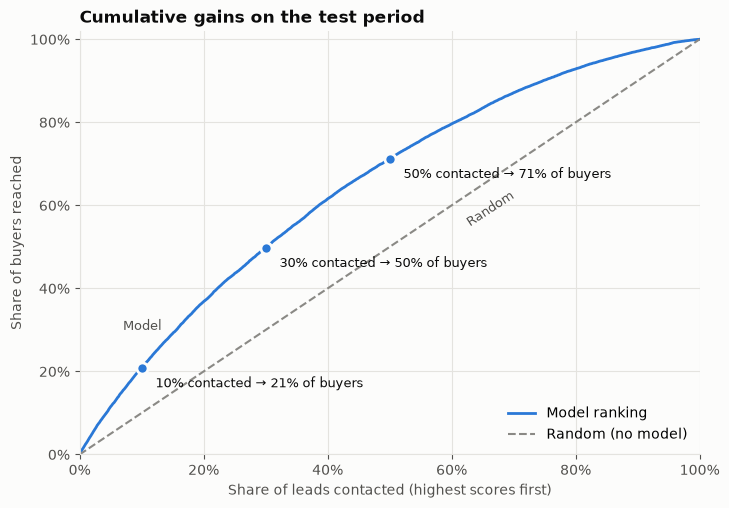

In [16]:
order = np.argsort(-scores_test)
y_sorted = y_test.to_numpy()[order]
share_contacted = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
share_buyers = np.cumsum(y_sorted) / y_sorted.sum()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(share_contacted, share_buyers, color=BLUE, label='Model ranking')
ax.plot([0, 1], [0, 1], color=GRAY, linestyle='--', linewidth=1.5, label='Random (no model)')
for share in (0.1, 0.3, 0.5):
    reached = share_buyers[int(share * len(share_buyers)) - 1]
    ax.plot(share, reached, 'o', markersize=8, color=BLUE, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f'{pct(share, 0)} contacted → {pct(reached, 0)} of buyers', (share, reached),
                xytext=(10, -14), textcoords='offset points', fontsize=9, color=INK)
ax.text(0.62, 0.55, 'Random', color=INK_2, fontsize=9, rotation=33)
ax.text(0.07, 0.3, 'Model', color=INK_2, fontsize=9)
ax.set_xlabel('Share of leads contacted (highest scores first)')
ax.set_ylabel('Share of buyers reached')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: pct(x, 0)))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: pct(x, 0)))
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title('Cumulative gains on the test period')
ax.legend(loc='lower right')
plt.show()

### 8.3 Lift by decile

In [17]:
deciles = pd.DataFrame({'bought': y_test.to_numpy(), 'score': scores_test})
deciles['decile'] = 10 - pd.qcut(deciles['score'].rank(method='first'), 10, labels=False)
lift = deciles.groupby('decile').agg(leads=('bought', 'size'), buyers=('bought', 'sum'),
                                     purchase_rate=('bought', 'mean'), mean_score=('score', 'mean'))
lift['lift'] = lift['purchase_rate'] / y_test.mean()
lift['cumulative_buyers'] = lift['buyers'].cumsum() / lift['buyers'].sum()
lift.index.name = 'decile (1 = highest scores)'
lift.style.format({'leads': '{:,}', 'buyers': '{:,}', 'purchase_rate': '{:.1%}', 'mean_score': '{:.3f}',
                   'lift': '{:.2f}x', 'cumulative_buyers': '{:.1%}'})

,leads,buyers,purchase_rate,mean_score,lift,cumulative_buyers
decile (1 = highest scores),,,,,,
1,"13,411","3,925",29.3%,0.286,2.09x,20.9%
2,"13,411","2,999",22.4%,0.206,1.59x,36.8%
3,"13,411","2,448",18.3%,0.165,1.30x,49.8%
4,"13,411","2,206",16.4%,0.136,1.17x,61.6%
5,"13,410","1,826",13.6%,0.114,0.97x,71.3%
6,"13,411","1,572",11.7%,0.095,0.84x,79.6%
7,"13,411","1,408",10.5%,0.079,0.75x,87.1%
8,"13,411","1,080",8.1%,0.065,0.57x,92.9%
9,"13,411",802,6.0%,0.050,0.43x,97.1%


The predicted scores (`mean_score`) track the observed purchase rate decile by decile, but they run **slightly low**:

- At the top they are close: 0.29 against 29% in the first decile.
- Further down they miss by 2 to 3 points, for example 0.14 against 16% in the fourth decile.
- On average the model predicts about 12%, the purchase rate of the training months, while the test months converted at 14%.

The scores can therefore be read as **approximate purchase probabilities** that understate the test period a little. The cost view in the next section uses them as probabilities, so its thresholds are slightly strict: with recalibrated scores, a few more leads would clear each one. In use, the scores should be recalibrated on recent months (see next steps).

### 8.4 Choosing how many leads to message

**Budget view.** If the company decides how many messages it can afford, the table shows what each budget buys:

In [18]:
budget = []
for share in (0.1, 0.2, 0.3, 0.5, 0.7, 1.0):
    n = int(share * len(y_sorted))
    budget.append({'leads messaged': pct(share, 0), 'messages': f'{n:,}',
                   'buyers reached': pct(y_sorted[:n].sum() / y_sorted.sum()),
                   'purchase rate among messaged': pct(y_sorted[:n].mean()),
                   'buyers reached without model': pct(share, 0)})
pd.DataFrame(budget).set_index('leads messaged')

,messages,buyers reached,purchase rate among messaged,buyers reached without model
leads messaged,,,,
10%,"13,410",20.9%,29.3%,10%
20%,"26,821",36.8%,25.8%,20%
30%,"40,232",49.8%,23.3%,30%
50%,"67,054",71.3%,20.0%,50%
70%,"93,876",87.1%,17.5%,70%
100%,"134,109",100.0%,14.0%,100%


**Cost view.** A lead is worth a message when its expected value exceeds the cost:

$$P(\text{buy}) \times \text{value per buyer reached} > \text{cost per message}$$

The challenge does not give these figures, so the values below are **hypothetical** and can be changed in the next cell.

The *value per buyer reached* is the key unknown. The full sale margin (R\$ 150 below) overstates it, because many of these leads would buy without the message. The table shows how the decision changes as that value falls. Measuring it properly needs an A/B test (see next steps).

In [19]:
COST_PER_MESSAGE = 0.50                    # R$, hypothetical
VALUES_PER_BUYER_REACHED = [150, 30, 10, 5]  # R$, hypothetical

decision = []
for value in VALUES_PER_BUYER_REACHED:
    threshold = COST_PER_MESSAGE / value
    selected = scores_test >= threshold
    decision.append({'value per buyer reached (R$)': value,
                     'minimum purchase probability': f'{threshold:.1%}',
                     'leads messaged': pct(selected.mean()),
                     'buyers reached': pct(y_test[selected].sum() / y_test.sum())})
pd.DataFrame(decision).set_index('value per buyer reached (R$)')

,minimum purchase probability,leads messaged,buyers reached
value per buyer reached (R$),,,
150,0.3%,100.0%,100.0%
30,1.7%,99.5%,99.9%
10,5.0%,85.3%,95.3%
5,10.0%,52.0%,73.1%


If a message is worth the full margin, the company should keep messaging everyone, because even the lowest-scored decile buys at about 4%. The model starts to matter as the value per buyer reached falls. At R\$ 10, it drops about 15% of the messages and keeps 95% of the buyers. At R\$ 5, it drops almost half of the messages and still reaches 73% of the buyers.

### 8.5 Classification metrics at the operating point

For a concrete reference, take the policy of **messaging the top 50% of leads**, which halves the cost. Treating "messaged" as the positive prediction:

In [20]:
cutoff = np.quantile(scores_test, 0.5)
y_pred = (scores_test >= cutoff).astype(int)

print(f'Precision: {precision_score(y_test, y_pred):.3f}  (base rate {y_test.mean():.3f})')
print(f'Recall:    {recall_score(y_test, y_pred):.3f}  (random: 0.500)')
print(f'F1 score:  {f1_score(y_test, y_pred):.3f}')

pd.DataFrame(confusion_matrix(y_test, y_pred),
             index=['actual: did not buy', 'actual: bought'],
             columns=['not messaged', 'messaged']).style.format('{:,}')

Precision: 0.200  (base rate 0.140)
Recall:    0.713  (random: 0.500)
F1 score:  0.312


,not messaged,messaged
actual: did not buy,"61,653","53,651"
actual: bought,"5,401","13,404"


## 9. What drives a purchase

**Permutation importance** measures how much the test average precision drops when one feature's values are shuffled. Original columns are permuted before encoding, so each categorical variable counts as a single feature. A random sample of 30,000 test leads keeps the computation fast.

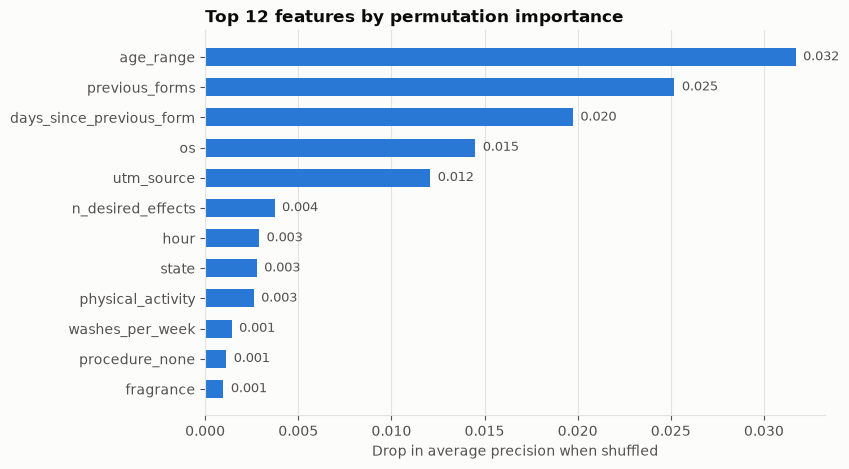

In [21]:
sample = X_test.sample(30000, random_state=RANDOM_STATE)
importance = permutation_importance(model, sample, y_test.loc[sample.index], scoring='average_precision',
                                    n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=X.columns).sort_values().tail(12)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
for y_pos, value in enumerate(importance.values):
    ax.text(value + 0.0004, y_pos, f'{value:.3f}', va='center', fontsize=9, color=INK_2)
ax.set_xlabel('Drop in average precision when shuffled')
ax.set_title('Top 12 features by permutation importance')
ax.grid(axis='y', visible=False)
plt.show()

The ranking confirms the exploratory analysis:

- **Age range** is the most important feature.
- **History** (previous forms and days since the last one) comes next: returning leads are much more likely to buy.
- **Device** (`os`) and **acquisition channel** (`utm_source`) carry clear signal.
- Questionnaire answers about the hair contribute little. They matter for personalizing the product, not for predicting the purchase.

## 10. Conclusions and next steps

**Conclusions**

- About **one in eight leads buys**. Age, return visits, device and acquisition channel separate buyers from non-buyers; the hair questionnaire itself barely does.
- The gradient boosting model ranks leads clearly better than random and better than a logistic regression. The top 10% of leads convert at about twice the average rate.
- The model does not make the purchase decision predictable lead by lead, but it is a useful **prioritization** tool. Halving the message volume while keeping roughly 70% of buyers is the kind of trade-off it enables.
- Whether to cut messages at all depends on how much a message actually adds to a sale, which the available data cannot tell.

**Next steps**

1. **Measure the effect of the message** with an A/B test (messaged vs. not messaged, by score band). This gives the real value per buyer reached and turns the model into an uplift model if needed.
2. **Add purchase history**: previous orders of the same customer, with their timestamps, are likely stronger signals than previous forms.
3. **Retrain monthly and monitor** the purchase rate, the score distribution and the calibration, given the drift between months. Recalibrating on the latest month keeps the scores usable as probabilities in the cost view.
4. **Score in real time** when a form is submitted, using the saved pipeline and the customer's form history.